# Recursion Cellular Image Classification — Final Kaggle Notebook

- uses all 6 microscopy channels
- uses both sites `s1` and `s2`
- averages validation/prediction probabilities across sites
- uses a CNN backbone modified for 6-channel input
- uses experiment-aware validation split
- reports Accuracy, Top-5 Accuracy, Macro F1, Weighted F1, and Micro F1


## 1. Imports and config

In [1]:
import os
import random
import gc
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.amp import autocast, GradScaler

import torchvision.models as models
from torchvision.models import EfficientNet_B0_Weights

from sklearn.model_selection import GroupKFold
from sklearn.metrics import accuracy_score, f1_score
from sklearn.preprocessing import LabelEncoder

from tqdm.auto import tqdm

pd.set_option("display.max_columns", 100)

In [2]:
class CFG:
    seed = 42

    data_path = "/kaggle/input/competitions/recursion-cellular-image-classification"

    fallback_data_path = "/kaggle/input/recursion-cellular-image-classification"

    img_size = 384
    batch_size = 16
    epochs = 10
    lr = 3e-4
    weight_decay = 1e-4
    num_workers = 2

    n_folds = 5
    fold = 0

    use_pretrained = True
    use_amp = True
    tta = 4

    device = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", CFG.device)
if CFG.device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [3]:
def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True

seed_everything(CFG.seed)

## 2. Data path setup

This keeps your original `DATA_PATH` style but also checks the common Kaggle path.

In [4]:
def resolve_data_path():
    if os.path.exists(CFG.data_path):
        return CFG.data_path
    if os.path.exists(CFG.fallback_data_path):
        return CFG.fallback_data_path
    raise FileNotFoundError(
        "Could not find competition data. Add the Recursion Cellular Image Classification dataset to this notebook."
    )

DATA_PATH = resolve_data_path()
print("DATA_PATH:", DATA_PATH)
print("Files:", os.listdir(DATA_PATH)[:20])

DATA_PATH: /kaggle/input/competitions/recursion-cellular-image-classification
Files: ['sample_submission.csv', 'pixel_stats.csv', 'train_controls.csv', 'test_controls.csv', 'train.csv', 'test.csv', 'recursion_dataset_license.pdf', 'test', 'train']


## 3. Load CSV files

In [5]:
train = pd.read_csv(os.path.join(DATA_PATH, "train.csv"))
test = pd.read_csv(os.path.join(DATA_PATH, "test.csv"))
sample = pd.read_csv(os.path.join(DATA_PATH, "sample_submission.csv"))

print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Sample shape:", sample.shape)
print("Train columns:", train.columns.tolist())
print("Test columns:", test.columns.tolist())

display(train.head())
display(test.head())

Train shape: (36517, 5)
Test shape: (19899, 4)
Sample shape: (19899, 2)
Train columns: ['id_code', 'experiment', 'plate', 'well', 'sirna']
Test columns: ['id_code', 'experiment', 'plate', 'well']


,id_code,experiment,plate,well,sirna
0,HEPG2-01_1_B03,HEPG2-01,1,B03,sirna_250
1,HEPG2-01_1_B04,HEPG2-01,1,B04,sirna_62
2,HEPG2-01_1_B05,HEPG2-01,1,B05,sirna_1115
3,HEPG2-01_1_B06,HEPG2-01,1,B06,sirna_602
4,HEPG2-01_1_B07,HEPG2-01,1,B07,sirna_529


,id_code,experiment,plate,well
0,HEPG2-08_1_B03,HEPG2-08,1,B03
1,HEPG2-08_1_B04,HEPG2-08,1,B04
2,HEPG2-08_1_B05,HEPG2-08,1,B05
3,HEPG2-08_1_B06,HEPG2-08,1,B06
4,HEPG2-08_1_B07,HEPG2-08,1,B07


## 4. Encode labels and create site rows

The CSV does **not** contain a `site` column. Images exist as `s1` and `s2`, so we manually create rows for both sites.

In [6]:
label_encoder = LabelEncoder()
train["label"] = label_encoder.fit_transform(train["sirna"])
NUM_CLASSES = train["label"].nunique()

print("Number of classes:", NUM_CLASSES)

train_s1 = train.copy()
train_s1["site"] = 1
train_s2 = train.copy()
train_s2["site"] = 2
train_site = pd.concat([train_s1, train_s2], ignore_index=True)

test_s1 = test.copy()
test_s1["site"] = 1
test_s2 = test.copy()
test_s2["site"] = 2
test_site = pd.concat([test_s1, test_s2], ignore_index=True)

print("Train site rows:", train_site.shape)
print("Test site rows:", test_site.shape)
train_site.head()

Number of classes: 1108
Train site rows: (73034, 7)
Test site rows: (39798, 5)


,id_code,experiment,plate,well,sirna,label,site
0,HEPG2-01_1_B03,HEPG2-01,1,B03,sirna_250,301,1
1,HEPG2-01_1_B04,HEPG2-01,1,B04,sirna_62,702,1
2,HEPG2-01_1_B05,HEPG2-01,1,B05,sirna_1115,128,1
3,HEPG2-01_1_B06,HEPG2-01,1,B06,sirna_602,684,1
4,HEPG2-01_1_B07,HEPG2-01,1,B07,sirna_529,604,1


## 5. Path helper and image check

if a channel image is missing, it uses a black image

In [7]:
def get_image_path(row, mode, site=None, channel=1):
    if site is None:
        site = int(row["site"])
    else:
        site = int(site)

    return os.path.join(
        DATA_PATH,
        mode,
        row["experiment"],
        f"Plate{int(row['plate'])}",
        f"{row['well']}_s{site}_w{channel}.png"
    )

example_row = train.iloc[0]
for site in [1, 2]:
    example_path = get_image_path(example_row, "train", site=site, channel=1)
    print(f"site {site} example path:", example_path)
    print("exists:", os.path.exists(example_path))

site 1 example path: /kaggle/input/competitions/recursion-cellular-image-classification/train/HEPG2-01/Plate1/B03_s1_w1.png
exists: True
site 2 example path: /kaggle/input/competitions/recursion-cellular-image-classification/train/HEPG2-01/Plate1/B03_s2_w1.png
exists: True


In [8]:
def load_6_channel_image(row, mode):
    site = int(row["site"])
    channels = []

    for channel in range(1, 7):
        path = get_image_path(row, mode, site=site, channel=channel)

        if os.path.exists(path):
            img = Image.open(path).convert("L")
        else:
            # Same idea as your attached notebook: do not crash on missing paths.
            img = Image.new("L", (512, 512), 0)

        img = img.resize((CFG.img_size, CFG.img_size))
        img = np.asarray(img, dtype=np.float32) / 255.0
        channels.append(img)

    image = np.stack(channels, axis=0)
    return image

## 6. Experiment-aware validation split

We split by experiment to reduce leakage between train and validation.

In [9]:
gkf = GroupKFold(n_splits=CFG.n_folds)
train["fold"] = -1

for fold, (_, val_idx) in enumerate(gkf.split(train, train["label"], groups=train["experiment"])):
    train.loc[val_idx, "fold"] = fold

train_site = train_site.merge(train[["id_code", "fold"]], on="id_code", how="left")

trn_df = train_site[train_site["fold"] != CFG.fold].reset_index(drop=True)
val_df = train_site[train_site["fold"] == CFG.fold].reset_index(drop=True)

print("Train rows:", trn_df.shape)
print("Val rows:", val_df.shape)
print("Unique val samples:", val_df["id_code"].nunique())

Train rows: (59740, 8)
Val rows: (13294, 8)
Unique val samples: 6647


## 7. Dataset and dataloaders

In [10]:
class RecursionDataset(Dataset):
    def __init__(self, df, mode="train", augment=False):
        self.df = df.reset_index(drop=True)
        self.mode = mode
        self.augment = augment

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = load_6_channel_image(row, self.mode)

        if self.augment:
            if random.random() < 0.5:
                image = image[:, :, ::-1].copy()
            if random.random() < 0.5:
                image = image[:, ::-1, :].copy()
            if random.random() < 0.5:
                k = random.randint(0, 3)
                image = np.rot90(image, k, axes=(1, 2)).copy()

        image = torch.tensor(image, dtype=torch.float32)

        if self.mode == "test":
            return image, row["id_code"]

        label = torch.tensor(int(row["label"]), dtype=torch.long)
        return image, label, row["id_code"]

In [11]:
train_ds = RecursionDataset(trn_df, mode="train", augment=True)
val_ds = RecursionDataset(val_df, mode="train", augment=False)

train_loader = DataLoader(
    train_ds,
    batch_size=CFG.batch_size,
    shuffle=True,
    num_workers=CFG.num_workers,
    pin_memory=True,
    drop_last=True,
)

val_loader = DataLoader(
    val_ds,
    batch_size=CFG.batch_size * 2,
    shuffle=False,
    num_workers=CFG.num_workers,
    pin_memory=True,
)

print("Batches:", len(train_loader), len(val_loader))

Batches: 3733 416


## 8. Model

EfficientNet-B0 is adapted from 3-channel RGB input to 6 microscopy channels.

In [12]:
class RecursionModel(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        weights = None
        if CFG.use_pretrained:
            try:
                weights = EfficientNet_B0_Weights.IMAGENET1K_V1
            except Exception:
                weights = None

        self.model = models.efficientnet_b0(weights=weights)

        old_conv = self.model.features[0][0]
        new_conv = nn.Conv2d(
            6,
            old_conv.out_channels,
            kernel_size=old_conv.kernel_size,
            stride=old_conv.stride,
            padding=old_conv.padding,
            bias=False,
        )

        with torch.no_grad():
            if old_conv.weight.shape[1] == 3:
                new_conv.weight[:, :3] = old_conv.weight
                new_conv.weight[:, 3:] = old_conv.weight
                new_conv.weight *= 0.5
            else:
                nn.init.kaiming_normal_(new_conv.weight, mode="fan_out", nonlinearity="relu")

        self.model.features[0][0] = new_conv
        in_features = self.model.classifier[1].in_features
        self.model.classifier[1] = nn.Linear(in_features, num_classes)

    def forward(self, x):
        return self.model(x)

model = RecursionModel(NUM_CLASSES).to(CFG.device)
print("Model ready")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 128MB/s] 


Model ready


## 9. Loss, optimizer, scheduler

In [13]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=CFG.lr, weight_decay=CFG.weight_decay)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CFG.epochs)
scaler = GradScaler("cuda", enabled=(CFG.device == "cuda" and CFG.use_amp))

## 10. Metrics helpers

Validation metrics are computed after averaging predictions for `s1` and `s2` of the same `id_code`.

In [14]:
def topk_accuracy_from_probs(y_true, probs, k=5):
    topk = np.argsort(probs, axis=1)[:, -k:]
    return np.mean([y in topk[i] for i, y in enumerate(y_true)])


def compute_metrics(y_true, probs):
    preds = probs.argmax(axis=1)
    return {
        "accuracy": accuracy_score(y_true, preds),
        "top5_accuracy": topk_accuracy_from_probs(y_true, probs, k=5),
        "macro_f1": f1_score(y_true, preds, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_true, preds, average="weighted", zero_division=0),
        "micro_f1": f1_score(y_true, preds, average="micro", zero_division=0),
    }

## 11. Training and validation functions

In [15]:
def train_one_epoch(model, loader):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels, _ in tqdm(loader, leave=False):
        images = images.to(CFG.device, non_blocking=True)
        labels = labels.to(CFG.device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with autocast("cuda", enabled=(CFG.device == "cuda" and CFG.use_amp)):
            logits = model(images)
            loss = criterion(logits, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * images.size(0)
        preds = logits.argmax(1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    return running_loss / total, correct / total


@torch.no_grad()
def validate_site_rows(model, loader):
    model.eval()
    total_loss = 0.0
    total_rows = 0

    all_ids = []
    all_labels = []
    all_probs = []

    for images, labels, ids in tqdm(loader, leave=False):
        images = images.to(CFG.device, non_blocking=True)
        labels = labels.to(CFG.device, non_blocking=True)

        with autocast("cuda", enabled=(CFG.device == "cuda" and CFG.use_amp)):
            logits = model(images)
            loss = criterion(logits, labels)
            probs = torch.softmax(logits, dim=1)

        total_loss += loss.item() * images.size(0)
        total_rows += images.size(0)

        all_ids.extend(list(ids))
        all_labels.extend(labels.cpu().numpy())
        all_probs.append(probs.cpu().numpy())

    probs = np.concatenate(all_probs, axis=0)

    pred_df = pd.DataFrame({"id_code": all_ids, "label": all_labels})
    prob_df = pd.DataFrame(probs, columns=[f"p{i}" for i in range(NUM_CLASSES)])
    pred_df = pd.concat([pred_df, prob_df], axis=1)

    grouped_probs = pred_df.groupby("id_code")[[f"p{i}" for i in range(NUM_CLASSES)]].mean().values
    grouped_labels = pred_df.groupby("id_code")["label"].first().values

    metrics = compute_metrics(grouped_labels, grouped_probs)
    metrics["loss"] = total_loss / total_rows
    return metrics

## 12. Train model

In [16]:
best_acc = -1
history = []

for epoch in range(1, CFG.epochs + 1):
    train_loss, train_acc = train_one_epoch(model, train_loader)
    val_metrics = validate_site_rows(model, val_loader)
    scheduler.step()

    row = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        **{f"val_{k}": v for k, v in val_metrics.items()},
    }
    history.append(row)

    print(
        f"Epoch {epoch}/{CFG.epochs} | "
        f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_metrics['loss']:.4f} | Val Acc: {val_metrics['accuracy']:.4f} | "
        f"Val Top5: {val_metrics['top5_accuracy']:.4f} | "
        f"Val Macro F1: {val_metrics['macro_f1']:.4f}"
    )

    if val_metrics["accuracy"] > best_acc:
        best_acc = val_metrics["accuracy"]
        torch.save(model.state_dict(), "/kaggle/working/best_model.pth")
        print("Best model saved")

history_df = pd.DataFrame(history)
display(history_df)
history_df.to_csv("/kaggle/working/training_history.csv", index=False)

  0%|          | 0/3733 [00:00<?, ?it/s]

  0%|          | 0/416 [00:00<?, ?it/s]

Epoch 1/10 | Train Loss: 6.0748 | Train Acc: 0.0361 | Val Loss: 5.4894 | Val Acc: 0.0904 | Val Top5: 0.2213 | Val Macro F1: 0.0744
Best model saved


  0%|          | 0/3733 [00:00<?, ?it/s]

  0%|          | 0/416 [00:00<?, ?it/s]

...

Epoch 9/10 | Train Loss: 1.2710 | Train Acc: 0.6990 | Val Loss: 2.7186 | Val Acc: 0.5369 | Val Top5: 0.7241 | Val Macro F1: 0.5278
Best model saved


  0%|          | 0/3733 [00:00<?, ?it/s]

  0%|          | 0/416 [00:00<?, ?it/s]

Epoch 10/10 | Train Loss: 1.1903 | Train Acc: 0.7195 | Val Loss: 2.6841 | Val Acc: 0.5460 | Val Top5: 0.7315 | Val Macro F1: 0.5377
Best model saved


,epoch,train_loss,train_accuracy,val_accuracy,val_top5_accuracy,val_macro_f1,val_weighted_f1,val_micro_f1,val_loss
0,1,6.074798,0.036147,0.090417,0.221303,0.074421,0.074432,0.090417,5.489393
1,2,4.463311,0.166722,0.230029,0.413871,0.220513,0.220546,0.230029,4.340528
2,3,3.465482,0.297532,0.318038,0.522190,0.307026,0.307072,0.318038,3.809220
3,4,2.808274,0.401721,0.398827,0.605536,0.389753,0.389762,0.398827,3.260598
4,5,2.323143,0.485317,0.437190,0.648714,0.430506,0.430510,0.437190,3.124066
5,6,1.947616,0.556791,0.488641,0.679254,0.481187,0.481226,0.488641,2.863974
6,7,1.646902,0.616495,0.512412,0.701068,0.508220,0.508269,0.512412,2.801023
7,8,1.419069,0.666890,0.525049,0.720325,0.516564,0.516619,0.525049,2.719724
8,9,1.270964,0.699002,0.536934,0.724086,0.527797,0.527839,0.536934,2.718621
9,10,1.190259,0.719462,0.545961,0.731458,0.537651,0.537701,0.545961,2.684128


## 13. Plot training history

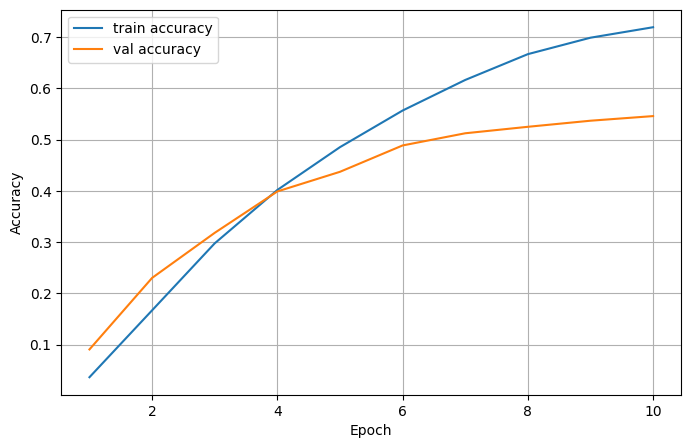

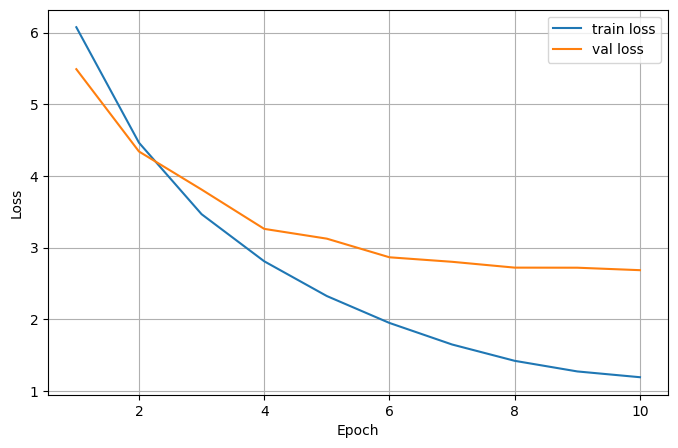

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(history_df["epoch"], history_df["train_accuracy"], label="train accuracy")
plt.plot(history_df["epoch"], history_df["val_accuracy"], label="val accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history_df["epoch"], history_df["train_loss"], label="train loss")
plt.plot(history_df["epoch"], history_df["val_loss"], label="val loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

## 14. TTA prediction

Predictions are averaged across TTA transforms and across `s1`/`s2` sites.

In [18]:
test_ds = RecursionDataset(test_site, mode="test", augment=False)
test_loader = DataLoader(
    test_ds,
    batch_size=CFG.batch_size * 2,
    shuffle=False,
    num_workers=CFG.num_workers,
    pin_memory=True,
)


def apply_tta(images, tta_id):
    if tta_id == 0:
        return images
    if tta_id == 1:
        return torch.flip(images, dims=[3])
    if tta_id == 2:
        return torch.flip(images, dims=[2])
    if tta_id == 3:
        return torch.rot90(images, k=1, dims=[2, 3])
    return images


@torch.no_grad()
def predict(model, loader):
    model.eval()
    all_ids = []
    all_probs = []

    for images, ids in tqdm(loader):
        images = images.to(CFG.device, non_blocking=True)
        probs_sum = 0

        for tta_id in range(CFG.tta):
            aug_images = apply_tta(images, tta_id)
            with autocast("cuda", enabled=(CFG.device == "cuda" and CFG.use_amp)):
                logits = model(aug_images)
                probs_sum += torch.softmax(logits, dim=1)

        probs = probs_sum / CFG.tta
        all_ids.extend(list(ids))
        all_probs.append(probs.cpu().numpy())

    probs = np.concatenate(all_probs, axis=0)
    pred_df = pd.DataFrame({"id_code": all_ids})
    prob_df = pd.DataFrame(probs, columns=[f"p{i}" for i in range(NUM_CLASSES)])
    pred_df = pd.concat([pred_df, prob_df], axis=1)

    grouped = pred_df.groupby("id_code")[[f"p{i}" for i in range(NUM_CLASSES)]].mean()
    return grouped

model.load_state_dict(torch.load("/kaggle/working/best_model.pth", map_location=CFG.device))
test_probs_df = predict(model, test_loader)
test_probs_df.head()

  0%|          | 0/1244 [00:00<?, ?it/s]

,p0,p1,p2,p3,p4,p5,p6,p7,p8,p9,p10,p11,p12,p13,p14,p15,p16,p17,p18,p19,p20,p21,p22,p23,p24,p25,p26,p27,p28,p29,p30,p31,p32,p33,p34,p35,p36,p37,p38,p39,p40,p41,p42,p43,p44,p45,p46,p47,p48,p49,...,p1058,p1059,p1060,p1061,p1062,p1063,p1064,p1065,p1066,p1067,p1068,p1069,p1070,p1071,p1072,p1073,p1074,p1075,p1076,p1077,p1078,p1079,p1080,p1081,p1082,p1083,p1084,p1085,p1086,p1087,p1088,p1089,p1090,p1091,p1092,p1093,p1094,p1095,p1096,p1097,p1098,p1099,p1100,p1101,p1102,p1103,p1104,p1105,p1106,p1107
id_code,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
HEPG2-08_1_B03,3.811805e-10,1.881115e-08,1.444654e-09,7.785099e-09,3.906097e-07,1.484235e-11,5.240493e-09,4.232322e-08,1.117259e-10,1.871802e-06,1.058676e-11,3.693883e-11,3.514562e-09,4.933028e-10,3.619045e-06,4.834932e-07,1.119589e-08,1.606894e-11,7.984556e-12,2.288112e-04,3.172786e-09,7.020383e-13,7.808345e-07,2.238199e-10,3.896233e-04,1.260534e-08,2.288683e-10,8.220595e-06,9.989025e-10,6.848822e-05,5.804935e-07,7.128750e-05,3.141055e-09,1.064865e-10,9.641767e-07,8.332542e-11,8.761491e-12,5.407205e-11,2.960020e-09,4.950468e-09,1.122791e-05,5.054674e-10,1.257558e-08,1.389582e-08,2.499148e-11,2.833686e-07,1.092243e-07,8.813089e-10,4.857783e-14,5.669572e-11,...,1.238766e-05,4.227746e-07,6.366366e-04,6.423130e-07,5.213904e-09,2.734935e-13,1.173323e-10,1.126753e-08,9.198772e-06,1.936663e-06,3.843337e-09,8.123769e-10,3.852597e-08,4.122424e-12,8.310232e-08,3.646707e-07,4.198702e-05,1.719298e-10,3.217866e-10,9.302048e-09,5.538966e-06,1.927656e-09,8.967140e-13,2.830891e-08,0.000060,1.227894e-09,1.632559e-06,6.913529e-11,1.937832e-08,2.415526e-09,2.407778e-09,4.083952e-06,4.206850e-06,4.425596e-07,3.184528e-07,4.847171e-12,3.976718e-06,3.917554e-08,1.061111e-04,8.163598e-13,2.581547e-08,8.208450e-06,1.442789e-08,2.097058e-08,6.014081e-09,2.462668e-11,2.954879e-07,7.815553e-05,1.686562e-08,5.802391e-09
HEPG2-08_1_B04,1.560101e-06,7.528039e-11,2.289283e-05,6.946855e-04,3.795133e-07,4.368485e-05,6.406810e-05,5.843769e-04,1.105032e-06,4.100997e-04,1.716820e-07,2.503796e-08,4.948943e-07,3.042896e-06,1.276292e-08,2.019342e-03,6.801468e-11,1.410977e-10,6.090461e-05,3.879427e-09,1.613629e-07,5.485800e-06,7.927964e-03,1.536316e-05,4.990215e-06,6.167987e-10,3.049354e-04,3.348030e-05,3.156033e-05,4.764042e-03,1.698175e-08,5.744173e-08,1.999583e-08,9.993748e-08,1.360139e-07,4.208807e-03,1.519248e-04,2.485445e-08,7.188439e-09,2.103792e-10,8.409058e-08,3.531468e-08,1.928058e-09,9.744574e-08,1.188485e-02,2.252794e-05,2.171284e-05,1.030947e-07,1.107172e-07,7.833733e-08,...,2.648283e-08,1.681770e-07,1.353095e-09,1.478578e-04,1.351799e-07,6.175391e-08,1.210943e-05,1.352401e-08,1.237815e-08,2.004206e-07,2.614135e-06,7.146163e-05,7.786703e-06,8.413334e-11,2.551896e-05,1.635991e-05,6.917213e-09,1.269945e-09,2.391722e-10,1.678046e-05,4.765204e-07,1.585702e-05,2.286338e-03,3.599524e-06,0.000746,3.328714e-05,4.423774e-06,1.730727e-04,3.826634e-06,4.353654e-06,7.695126e-06,3.223768e-10,5.635238e-08,3.435909e-10,1.886983e-06,6.076194e-07,6.379568e-04,1.188055e-04,9.888679e-07,2.279916e-05,1.893250e-04,1.840352e-05,1.786401e-08,2.859336e-03,1.041599e-05,1.692945e-04,2.694563e-08,9.619328e-08,2.330270e-09,4.117544e-05
HEPG2-08_1_B05,8.159994e-07,1.826989e-10,2.571054e-08,4.011702e-08,4.133552e-06,8.672649e-05,2.045829e-07,1.709845e-09,1.521441e-06,5.737834e-10,2.057825e-10,4.190360e-09,7.228584e-04,6.842099e-07,1.461416e-05,1.613182e-09,1.868944e-09,4.849153e-05,1.432816e-08,2.968404e-07,1.713683e-07,8.559663e-10,3.968984e-05,3.278952e-07,3.539439e-05,5.690549e-06,8.040072e-09,5.929951e-10,6.580554e-07,9.641464e-03,1.401427e-07,1.212797e-05,1.134011e-06,5.960226e-08,7.326120e-05,1.474129e-07,6.990637e-09,6.789721e-07,2.223394e-10,2.570684e-10,6.511144e-05,5.871720e-10,8.393988e-13,7.705944e-06,1.291712e-06,5.594123e-10,1.589890e-09,2.036428e-04,7.279289e-09,9.448119e-08,...,3.496681e-06,2.761076e-03,2.256557e-08,1.185736e-07,1.338163e-08,2.068896e-12,6.039325e-08,1.1401

## 15. Create submission.csv

In [19]:
pred_labels = test_probs_df.values.argmax(axis=1)
pred_sirna = label_encoder.inverse_transform(pred_labels)

submission = pd.DataFrame({
    "id_code": test_probs_df.index,
    "sirna": pred_sirna,
})

# Keep original sample order.
submission = sample[["id_code"]].merge(submission, on="id_code", how="left")

# Fill missing predictions with most common class, but keep as string.
submission["sirna"] = submission["sirna"].fillna(train["sirna"].mode()[0])

submission.to_csv("/kaggle/working/submission.csv", index=False)

print(submission.shape)
display(submission.head())
print(submission["sirna"].head())

(19899, 2)


,id_code,sirna
0,HEPG2-08_1_B03,sirna_91
1,HEPG2-08_1_B04,sirna_659
2,HEPG2-08_1_B05,sirna_911
3,HEPG2-08_1_B06,sirna_823
4,HEPG2-08_1_B07,sirna_848


0     sirna_91
1    sirna_659
2    sirna_911
3    sirna_823
4    sirna_848
Name: sirna, dtype: object
